# v2 - Sile Main Canal (USGS): de video de dron a caudal con LSPIV

Mide el caudal del Sile Main Canal (Cochiti, Nuevo Mexico) a partir de un video de **dron en vuelo
estacionario mirando hacia abajo**, con LSPIV de **pyorc**. Los datos son del data release del USGS
*"Small Unoccupied Aircraft System Imagery and Associated Data used for Discharge Measurement at
Eight Locations Across the United States in 2019 and 2020"* (DOI
[10.5066/P9H2MM1M](https://doi.org/10.5066/P9H2MM1M)).

Es el codigo de la **v1** (Ngwerere) llevado a un caso de campo real: mismo pipeline de pyorc, datos
de otra procedencia y, por primera vez, una **referencia independiente** (aforo ADV por vadeo, con
incertidumbre ISO declarada del 4.2 %), que no se abre hasta la Parte 7.

**Los datos de entrada se leen en modo solo lectura. Todo lo que este notebook genera se escribe en
`salidas/`.** Las lineas de codigo que cambian respecto a la v1 llevan la marca `# [v2]`.

---
## Que cambia respecto a v1

| Parte | v1 (Ngwerere) | v2 (Sile Main Canal) | Por que lo obliga este caso |
|---|---|---|---|
| 0 | datos de Ngwerere | datos del USGS y video **ya estabilizado**; modulo `benchmark` | el dron se mueve (ver Parte 1) y el video 4K es caro |
| 2 | 4 GCPs RTK en UTM 35S | **2 puntos** sobre las lineas de agua, coordenadas locales | no hay GCPs: solo el ancho conocido del canal (1.8288 m); con 2 puntos pyorc activa el modo cenital |
| 3 | `crs=32735`, 0.01 m/px, ventana 25 px, AOI a mano | `crs=None`, **0.004 m/px**, ventana **32 px**, AOI por dentro de las lineas de agua | el canal es diez veces mas estrecho que el rio de v1 |
| 4 | 125 fotogramas, `stabilize=` dentro de pyorc | **250** fotogramas, sin `stabilize=`; cada etapa cronometrada | la estabilizacion de pyorc tarda minutos en 4K y se hizo una vez fuera |
| 4b | la mascara de angulo se calculaba y se descartaba | **se aplica**, con la direccion leida del propio campo | v1 reproducia un ejemplo publicado; aqui no hay esa atadura y el canal es recto |
| 5 | batimetria RTK `x, y, z`, remuestreada | seccion del CSV (progresiva y calado), **13 verticales exactas** (`s=`), `V_CORR` **0.92** | la seccion del aforo tiene 13 puntos: remuestrear inventaria geometria |
| 5 | la referencia se comparaba alli mismo | el caudal se calcula sin mirar ninguna referencia | la referencia ahora es un aforo independiente |
| 6 | (no existia) | **recursos** por etapa | 4K: el pico de memoria decide si cabe |
| 7 | (no existia) | **comparacion con el aforo ADV** y con el LSPIV del USGS, al final y una sola vez | primera referencia de campo |

**Lo que no cambia:** la cadena de pyorc (`Video` -> `normalize` -> `project` -> `get_piv`), las
mascaras y su orden, `get_transect` + `get_q(fill_method="log_interp")` + `get_river_flow`, y todas
las figuras de control de la v1.

---
## Parte 0 - Rutas de trabajo

Todas las rutas son relativas a esta carpeta, que es desde donde se ejecuta el notebook.

El video que se procesa **no** es el del data release sino su version estabilizada, la misma que usa
`casos/02_smc_pyorc` (se lee de alli, no se copia: pesa 1.1 GB). La genera
`herramientas/estabilizar_video.py`, que usa las mismas funciones internas de pyorc (`get_ms_gftt`
y `transform`) que el argumento `stabilize=` de la v1, una sola vez y con codec FFV1 sin perdida:

```
python herramientas/estabilizar_video.py datos/USGS/Video/SMC_D_RC_022_08172020_AC.mp4 \
    casos/02_smc_pyorc/entradas/SMC_estabilizado.mkv --poligono "0,420 3840,420 3840,1500 0,1500" --fin 249
```

Aqui **solo hay rutas**: los datos de validacion aparecen por primera vez en la Parte 7.

In [1]:
from pathlib import Path

import benchmark  # [v2] modulo local (benchmark.py, en esta misma carpeta)

# --- Entradas (nunca se modifican) ---
DIR_DATOS = Path("../../datos/USGS")                                  # [v2]
ARCHIVO_SECCION = DIR_DATOS / "Station_Stage_SileCanal.csv"          # [v2] progresiva y calado
ARCHIVO_PIV_USGS = DIR_DATOS / "SMC_PIV_results.mat"                 # [v2] LSPIV del USGS, Parte 7
# [v2] Video ya estabilizado (FFV1 sin perdida), compartido con casos/02_smc_pyorc.
ARCHIVO_VIDEO = Path("../../casos/02_smc_pyorc/entradas/SMC_estabilizado.mkv")

# --- Salidas ---
DIR_SALIDA = Path("salidas")
# exist_ok=True evita el error si la carpeta ya existe de una ejecucion anterior.
DIR_SALIDA.mkdir(exist_ok=True)

SALIDA_CAM_CONFIG = DIR_SALIDA / "cam_config.json"         # configuracion de camara
SALIDA_PIV_CRUDO = DIR_SALIDA / "piv_crudo.nc"             # velocimetria sin filtrar
SALIDA_PIV_FILTRADO = DIR_SALIDA / "piv_filtrado.nc"       # velocimetria con mascaras
SALIDA_TRANSECTO = DIR_SALIDA / "transecto_caudal.nc"      # transecto con q y v_eff
SALIDA_RESUMEN = DIR_SALIDA / "caudal_resumen.csv"         # tabla final de caudales
SALIDA_BENCHMARK = DIR_SALIDA / "benchmark_recursos.csv"   # [v2] coste de cada etapa

# [v2] Se vacian las mediciones por si el notebook se reejecuta sin reiniciar el kernel.
benchmark.reiniciar()

print("Datos de entrada:", DIR_DATOS)
print("Salidas en:      ", DIR_SALIDA)
# Se comprueba de una vez que las entradas existen, antes de procesar nada. Si aparece FALTA,
# el notebook se lanzo desde otra carpeta.
for entrada in (ARCHIVO_VIDEO, ARCHIVO_SECCION, ARCHIVO_PIV_USGS):     # [v2]
    print(f"  {'OK   ' if entrada.exists() else 'FALTA'} {entrada.name}")

Datos de entrada: ..\..\datos\USGS
Salidas en:       salidas
  OK    SMC_estabilizado.mkv
  OK    Station_Stage_SileCanal.csv
  OK    SMC_PIV_results.mat


---
## Parte 1 - Lectura del video

`pyorc.Video` envuelve el video y controla que rango de fotogramas se procesa. Aqui se lee un
solo fotograma en color para poder identificar visualmente los puntos de control.

Un dron en vuelo estacionario nunca esta quieto: en el video crudo el salto entre fotogramas
consecutivos es de 0.51 px de mediana, frente a los ~18 px que avanza el agua, y el PIV lo suma a la
velocidad. Por eso el video llega ya estabilizado (Parte 0): el temblor queda en 0.10 px.

Scanning video:   0%|          | 0/2 [00:00<?, ?it/s]

Scanning video:  50%|█████     | 1/2 [00:01<00:01,  1.91s/it]

Scanning video: 100%|██████████| 2/2 [00:02<00:00,  1.35s/it]

Scanning video: 100%|██████████| 2/2 [00:08<00:00,  4.08s/it]

Dimensiones del fotograma: (2160, 3840, 3)
FPS del video: 30.015


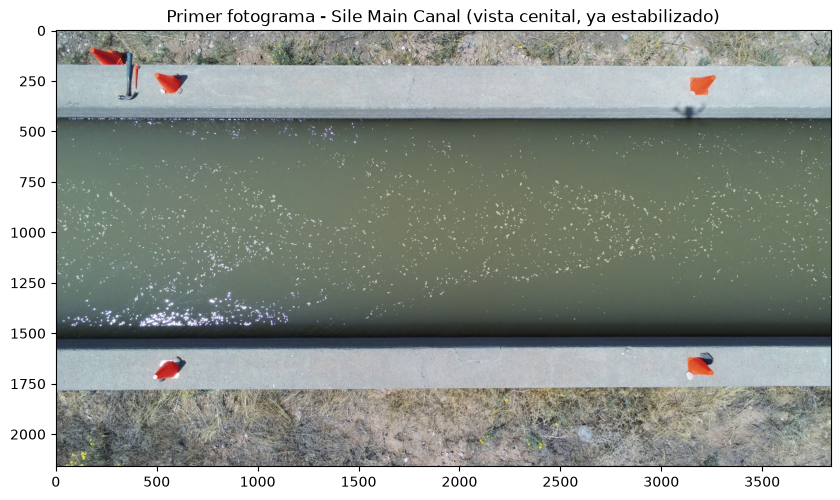

In [2]:
import matplotlib.pyplot as plt
import pyorc

# start_frame/end_frame limitan la lectura: para elegir los GCPs basta con un fotograma.
video = pyorc.Video(str(ARCHIVO_VIDEO), start_frame=0, end_frame=1)

# get_frame devuelve un array numpy. method="rgb" mantiene el color (por defecto seria gris,
# que es lo que usa el PIV, pero el color ayuda a ver los marcadores).
frame = video.get_frame(0, method="rgb")

# Forma (filas, columnas, canales): las filas son la altura y las columnas el ancho.
print(f"Dimensiones del fotograma: {frame.shape}")
print(f"FPS del video: {video.fps}")

plt.figure(figsize=(10, 6))
plt.imshow(frame)
plt.title("Primer fotograma - Sile Main Canal (vista cenital, ya estabilizado)")   # [v2]
plt.savefig(DIR_SALIDA / "fig1_fotograma.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 2 - Puntos de control: de pixeles a metros

En una vista cenital no hay perspectiva que resolver: la relacion entre pixeles y metros es una
**escala mas una rotacion**. pyorc lo sabe, y si se le pasan exactamente **2 puntos** activa el modo
`is_nadir` y construye la transformacion con `estimateAffinePartial2D`, sin coordenadas RTK.

Los 2 puntos son los extremos de una distancia conocida: el **ancho de la lamina de agua**, 1.8288 m
(6 ft), el `Total Width` de la seccion del aforo. Van sobre la **linea de agua**, donde la lamina toca
el muro, no sobre el coronamiento.

**Es la constante mas influyente del notebook**: toda la velocidad, y con ella todo el caudal, es
proporcional a la escala. Diez pixeles de error son un 1 % en el caudal.

Ancho del canal en la imagen: 1025 px
Escala resultante:            1.784 mm/px
Incertidumbre si la linea de agua se lee con 5 px de error: 0.49 % en el caudal


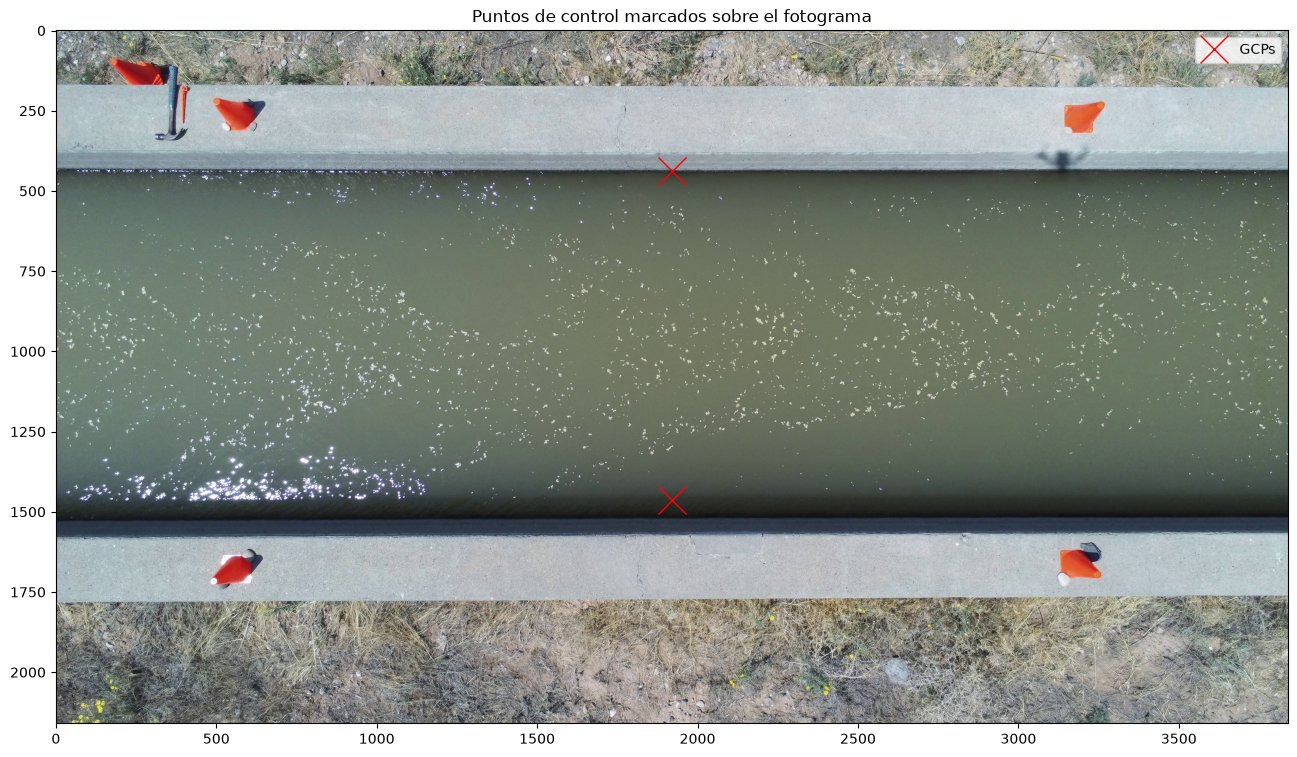

In [3]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Los dos puntos de control y la distancia real entre ellos       [v2]
# ---------------------------------------------------------------------------------------
# Columna de la imagen sobre la que se leen las dos lineas de agua: el centro del fotograma,
# lejos de los bordes, donde la distorsion de lente es minima.
COLUMNA_GCP = 1920
# Fila de la linea de agua contra el muro superior.
FILA_AGUA_SUP = 438
# Fila de la linea de agua contra el muro inferior. Aqui no hay escalon de brillo (el
# hormigon queda en sombra y se confunde con el agua), asi que se lee por el criterio fisico
# de que el agua se mueve y el hormigon no: la desviacion tipica temporal por fila, sobre las
# columnas 600-3400, cae de 7.1 a 1.3 niveles de gris entre las filas 1460 y 1465 y cruza el
# punto medio en la 1463.
FILA_AGUA_INF = 1463
# Ancho real de la lamina de agua entre esas dos lineas.  (obtenido del dataset)
ANCHO_CANAL = 1.8288          # m, 6 ft exactos
# ---------------------------------------------------------------------------------------

gcps = dict(
    # [v2] Solo DOS puntos: con eso pyorc activa el modo nadir. Ambos en la misma columna,
    # para que el segmento sea perpendicular a los muros.
    src=[
        [COLUMNA_GCP, FILA_AGUA_SUP],
        [COLUMNA_GCP, FILA_AGUA_INF],
    ],
    # [v2] Sus coordenadas en un sistema local en metros: origen en el muro superior y eje y
    # cruzando el canal. El eje x queda a lo largo del canal.
    dst=[
        [0.0, 0.0],
        [0.0, ANCHO_CANAL],
    ],
    h_ref=0.0,   # nivel local de referencia durante el video (0 al procesar un solo video)
    z_0=0.0,     # [v2] datum arbitrario: la superficie del agua es la cota cero
)

ANCHO_CANAL_PX = FILA_AGUA_INF - FILA_AGUA_SUP                 # [v2]
ESCALA = ANCHO_CANAL / ANCHO_CANAL_PX                          # [v2] m/px de la imagen original
print(f"Ancho del canal en la imagen: {ANCHO_CANAL_PX} px")
print(f"Escala resultante:            {ESCALA * 1000:.3f} mm/px")
print(f"Incertidumbre si la linea de agua se lee con 5 px de error: "
      f"{100 * 5 / ANCHO_CANAL_PX:.2f} % en el caudal")

plt.figure(figsize=(16, 9))
plt.imshow(frame)
# zip(*gcps["src"]) separa la lista de pares en dos secuencias (columnas, filas);
# el * delante las pasa a plot como los argumentos x e y.
plt.plot(*zip(*gcps["src"]), "rx", markersize=20, label="GCPs")
plt.legend()
plt.title("Puntos de control marcados sobre el fotograma")
plt.savefig(DIR_SALIDA / "fig2_puntos_control.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 3 - Configuracion de camara y reproyeccion

`CameraConfig` recibe los 2 puntos y `crs=None`, porque las coordenadas son locales. Los dos
parametros de la malla se redimensionan por geometria, no por resultado:

- **`RESOLUCION`**: con los 0.01 m/px de la v1 el canal quedaria en 183 px de ancho. Con 0.004 m/px
  quedan 457 px.
- **`VENTANA_PIV`**: 32 px a 0.004 m/px son 12.8 cm, unos 28 vectores cruzando el canal. El agua
  avanza ~8 px reproyectados por fotograma: la ventana tiene que ser bastante mayor, y lo es.

El **area de interes** se mete por dentro de las dos lineas de agua: el hormigon esta quieto y daria
vectores de velocidad nula que el filtrado no siempre elimina.

Area de interes: 5.00 m a lo largo x 1.75 m de ancho
  vectores a lo ancho del canal: ~28


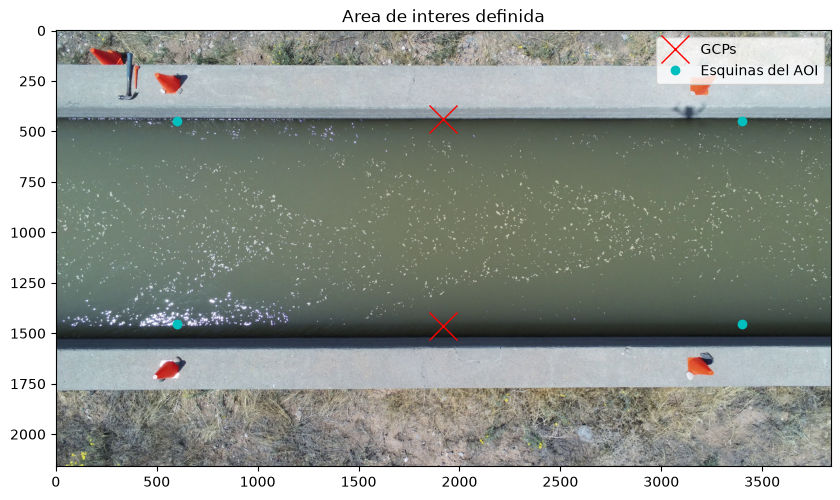

Configuracion guardada en: salidas\cam_config.json


In [4]:
import numpy as np   # [v2]

# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Malla de reproyeccion y area de interes
# ---------------------------------------------------------------------------------------
# Resolucion de la imagen ortorrectificada. 0.004 m/px deja el canal en ~457 px de ancho.
RESOLUCION = 0.004            # m/px   [v2]
# Ventana de interrogacion del PIV, en pixeles reproyectados. 32 px = 12.8 cm.
VENTANA_PIV = 32              # px     [v2]
# [v2] Tramo de columnas util de la imagen. Mas largo da mejor estadistica, pero se acerca a
# los bordes, donde la distorsion de la lente del dron es mayor y no hay modelo para corregirla.
COLUMNA_INI, COLUMNA_FIN = 600, 3400
# [v2] Las cuatro esquinas del area de interes, en pixeles [columna, fila]: unos 12 px por
# dentro de cada linea de agua para que las ventanas de interrogacion no toquen el muro.
ESQUINAS_AOI = [
    [COLUMNA_INI, FILA_AGUA_SUP + 12],
    [COLUMNA_FIN, FILA_AGUA_SUP + 12],
    [COLUMNA_FIN, FILA_AGUA_INF - 10],
    [COLUMNA_INI, FILA_AGUA_INF - 10],
]
# ---------------------------------------------------------------------------------------

# height y width se toman del propio fotograma para no escribirlos a mano.
cam_config = pyorc.CameraConfig(
    height=frame.shape[0],   # 2160 filas
    width=frame.shape[1],    # 3840 columnas
    gcps=gcps,               # los puntos de control definidos arriba
    crs=None,                # [v2] coordenadas locales en metros: no hay CRS geografico
)
cam_config.set_bbox_from_corners(ESQUINAS_AOI)
cam_config.resolution = RESOLUCION
cam_config.window_size = VENTANA_PIV

# [v2] El bbox ya esta en coordenadas locales; de aqui sale donde colocar el transecto.
x_bbox, y_bbox = np.array(cam_config.bbox.exterior.coords).T
print(f"Area de interes: {x_bbox.max() - x_bbox.min():.2f} m a lo largo x "
      f"{y_bbox.max() - y_bbox.min():.2f} m de ancho")
print(f"  vectores a lo ancho del canal: ~{int(ANCHO_CANAL / RESOLUCION / (VENTANA_PIV / 2))}")

plt.figure(figsize=(10, 6))
plt.imshow(frame)
plt.plot(*zip(*gcps["src"]), "rx", markersize=20, label="GCPs")
plt.plot(*zip(*ESQUINAS_AOI), "co", label="Esquinas del AOI")
plt.legend()
plt.title("Area de interes definida")
plt.savefig(DIR_SALIDA / "fig3_area_interes.png", dpi=110, bbox_inches="tight")
plt.show()

# Se guarda en JSON dentro de salidas/.
cam_config.to_file(str(SALIDA_CAM_CONFIG))
print(f"Configuracion guardada en: {SALIDA_CAM_CONFIG}")

Scanning video:   0%|          | 0/2 [00:00<?, ?it/s]

Scanning video:  50%|█████     | 1/2 [00:02<00:02,  2.10s/it]

Scanning video: 100%|██████████| 2/2 [00:02<00:00,  1.07s/it]

Scanning video: 100%|██████████| 2/2 [00:07<00:00,  3.68s/it]

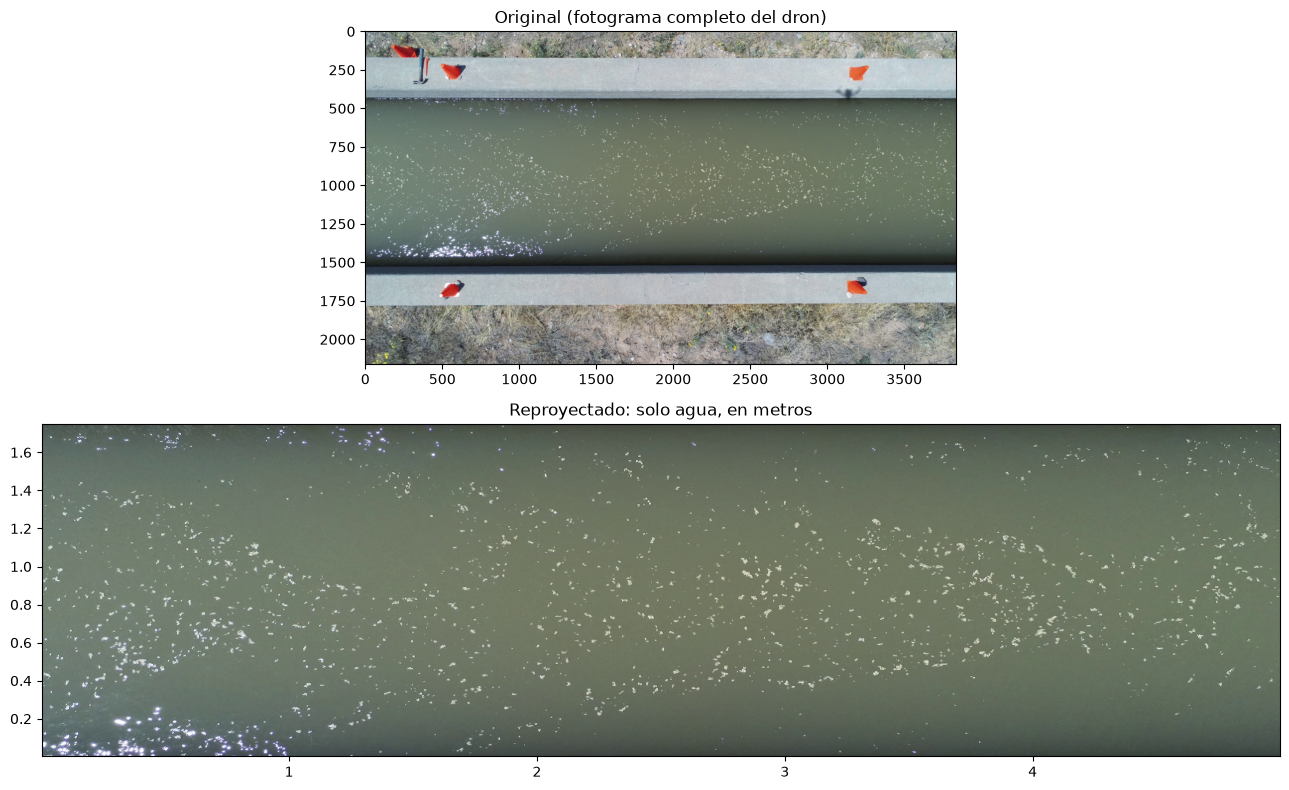

In [5]:
# Comprobacion visual de que la reproyeccion funciona, con un solo fotograma.
video_demo = pyorc.Video(
    str(ARCHIVO_VIDEO),
    camera_config=cam_config,  # al pasar la config, los frames ya saben reproyectarse
    start_frame=0,
    end_frame=1,
    h_a=0.0,                   # nivel del agua de ESTE video respecto a h_ref (mismo video: 0)
)

# get_frames devuelve un xarray.DataArray perezoso (dask); nada se calcula todavia.
da_rgb_demo = video_demo.get_frames(method="rgb")

# .frames es el accesor que pyorc registra en xarray; project ortorrectifica a la malla del AOI.
da_rgb_proj_demo = da_rgb_demo.frames.project()

fig, axes = plt.subplots(2, 1, figsize=(13, 8))   # [v2] el canal es alargado: uno sobre otro
axes[0].imshow(frame)
axes[0].set_title("Original (fotograma completo del dron)")   # [v2]
# Aqui si se fuerza el calculo, porque hay que dibujar los pixeles.
da_rgb_proj_demo[0].frames.plot(ax=axes[1])
axes[1].set_title("Reproyectado: solo agua, en metros")       # [v2]
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig4_reproyeccion.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4 - Velocidades superficiales con LSPIV

La cadena es la de la v1: pasar a gris, normalizar, reproyectar y correlacionar pares de fotogramas
consecutivos. No se pasa `stabilize=`, porque el video de entrada viene corregido.

Se procesan 250 de los 672 fotogramas disponibles (8.3 s): el doble que en la v1, porque hay margen
y promediar mas tiempo estabiliza los cuantiles.

Cada bloque va envuelto en `benchmark.medir(...)`. Medido sobre pyorc 0.9.8, `get_piv` **calcula en
el momento** (devuelve arrays de numpy, no de dask) pese a lo que dice su documentacion: el pico de
memoria del notebook se alcanza ahi.

In [6]:
from dask.diagnostics import ProgressBar

# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Cuanto video se procesa
# ---------------------------------------------------------------------------------------
# [v2] 250 fotogramas a 30 fps son 8.3 s de video. Mas fotogramas estabilizan los cuantiles y
# cuestan tiempo y memoria de forma casi lineal.
N_FRAMES = 250
# [v2] Ya no hay poligono de estabilizacion: el video llega estabilizado (Parte 0).
# ---------------------------------------------------------------------------------------

# Se recarga la configuracion desde el JSON recien escrito. Es la prueba de que el archivo
# guardado es completo y de que a partir de aqui no depende nada de las celdas anteriores.
cam_config = pyorc.load_camera_config(str(SALIDA_CAM_CONFIG))

with benchmark.medir("Parte 4: abrir video y get_frames", n_frames=N_FRAMES):      # [v2]
    video = pyorc.Video(
        str(ARCHIVO_VIDEO),
        camera_config=cam_config,
        start_frame=0,
        end_frame=N_FRAMES,
        # [v2] Sin stabilize=: el video de entrada ya viene corregido.
        h_a=0.0,                         # nivel del agua igual al de la medicion de los GCPs
    )
    # Sin method="rgb" los fotogramas salen en escala de grises, que es lo que necesita el PIV.
    da = video.get_frames()

with benchmark.medir("Parte 4: normalize + project", n_frames=N_FRAMES):           # [v2]
    # Resta el fondo (media de varios fotogramas) para realzar los trazadores en movimiento.
    da_norm = da.frames.normalize()
    # Ortorrectifica cada fotograma a la malla del AOI. method="numpy" es la implementacion
    # vectorizada; sin ese argumento se usa la de OpenCV.
    da_norm_proj = da_norm.frames.project(method="numpy")

print("Calculando velocidades (PIV)...")
with benchmark.medir("Parte 4: get_piv", n_frames=N_FRAMES), ProgressBar():        # [v2]
    piv = da_norm_proj.frames.get_piv()

with benchmark.medir("Parte 4: to_netcdf", n_frames=N_FRAMES):                     # [v2]
    # to_netcdf escribe el resultado a disco.
    piv.to_netcdf(SALIDA_PIV_CRUDO)
print(f"Velocimetria cruda guardada en: {SALIDA_PIV_CRUDO}")

Scanning video:   0%|          | 0/251 [00:00<?, ?it/s]

Scanning video:   0%|          | 1/251 [00:01<07:00,  1.68s/it]

Scanning video:   1%|          | 2/251 [00:02<05:34,  1.34s/it]

Scanning video:   1%|          | 3/251 [00:03<03:44,  1.10it/s]

Scanning video:   2%|▏         | 4/251 [00:04<03:38,  1.13it/s]

...

[########################################] | 100% Completed | 100.12 s

Computing PIV per chunk: 100%|██████████| 1/1 [02:09<00:00, 129.11s/it]

Computing PIV per chunk: 100%|██████████| 1/1 [02:09<00:00, 129.12s/it]

  [bench] Parte 4: get_piv: 129.1 s | CPU 1318.2 s (10.2 nucleos) | RAM pico 14045 MB


  [bench] Parte 4: to_netcdf: 0.3 s | CPU 0.3 s (0.9 nucleos) | RAM pico 1978 MB
Velocimetria cruda guardada en: salidas\piv_crudo.nc


Dimensiones del resultado PIV: {'time': 250, 'y': 26, 'x': 77}


Scanning video:   0%|          | 0/2 [00:00<?, ?it/s]

Scanning video:  50%|█████     | 1/2 [00:00<00:00,  1.11it/s]

Scanning video: 100%|██████████| 2/2 [00:01<00:00,  1.56it/s]

Scanning video: 100%|██████████| 2/2 [00:04<00:00,  2.32s/it]

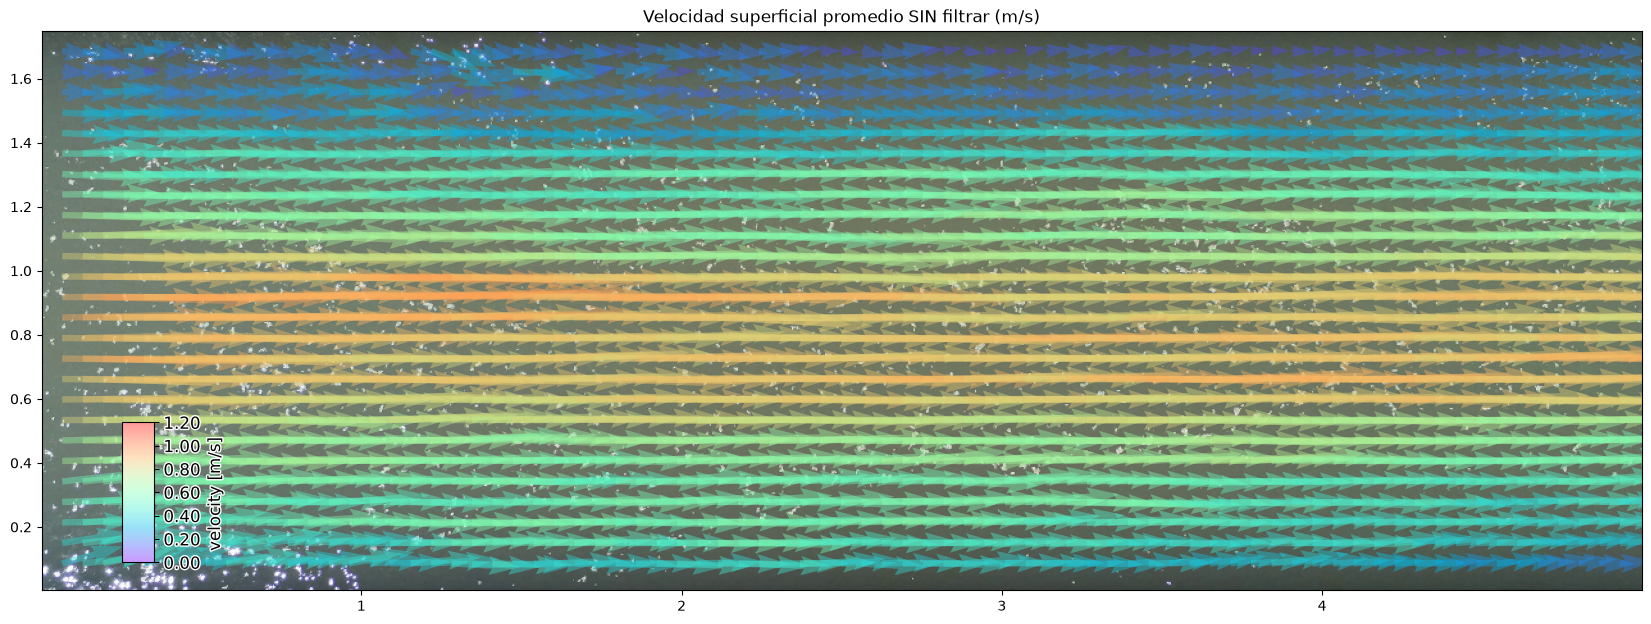

In [7]:
import xarray as xr
from matplotlib.colors import Normalize

# Se relee desde el NetCDF: el dataset trae v_x, v_y, s2n y corr, mas la config de camara
# embebida en los atributos.
ds = xr.open_dataset(SALIDA_PIV_CRUDO)
print(f"Dimensiones del resultado PIV: {dict(ds.sizes)}")

# Se reabre el video para tener un fotograma en color como fondo.
video_rgb = pyorc.Video(str(ARCHIVO_VIDEO), start_frame=0, end_frame=1)
# La config de camara se recupera del propio dataset, no hay que volver a construirla.
video_rgb.camera_config = ds.velocimetry.camera_config
da_rgb = video_rgb.get_frames(method="rgb")
da_rgb_proj = da_rgb.frames.project()

# No se pueden dibujar tres dimensiones a la vez, asi que se promedia en el tiempo.
# keep_attrs=True conserva la config de camara y los metadatos, que hacen falta para plotear.
ds_mean = ds.mean(dim="time", keep_attrs=True)

# [v2] Escala de color de 0 a 1.2 m/s: aqui el agua va a ~0.95 m/s, frente a 0.6 en la v1.
NORMA_COLOR = Normalize(vmin=0.0, vmax=1.2, clip=False)

p = da_rgb_proj[0].frames.plot()          # fondo ortorrectificado en color
ds_mean.velocimetry.plot(ax=p.axes, alpha=0.4, norm=NORMA_COLOR, add_colorbar=True)
plt.title("Velocidad superficial promedio SIN filtrar (m/s)")
plt.savefig(DIR_SALIDA / "fig5_velocidades_sin_filtrar.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4b - Filtrado de velocidades espurias

Las mismas mascaras que en la v1 y en el mismo orden, con sus parametros por defecto, salvo una
decision que si es de este caso:

- **La mascara de angulo se aplica.** En la v1 se calculaba y se descartaba para reproducir el
  resultado publicado del ejemplo. Aqui no hay esa atadura, y el caso la pide: un canal recto de
  hormigon con flujo unidireccional. Tolerancia por defecto, 0.25*pi (45 grados).
- **La direccion esperada se deduce del propio campo.** El signo del eje x local depende del orden
  en que se marcaron los dos puntos de control; se toma del signo de la velocidad media, que no es
  un ajuste: es leer en que direccion va el agua.

Velocidad media v_x = +0.589 m/s -> angle_expected = 1.571 rad


  [bench] Parte 4b: mascaras de filtrado: 0.5 s | CPU 0.5 s (1.0 nucleos) | RAM pico 1138 MB
Vectores validos antes del filtrado: 496249
Vectores validos despues:            283635 (57.2 %)


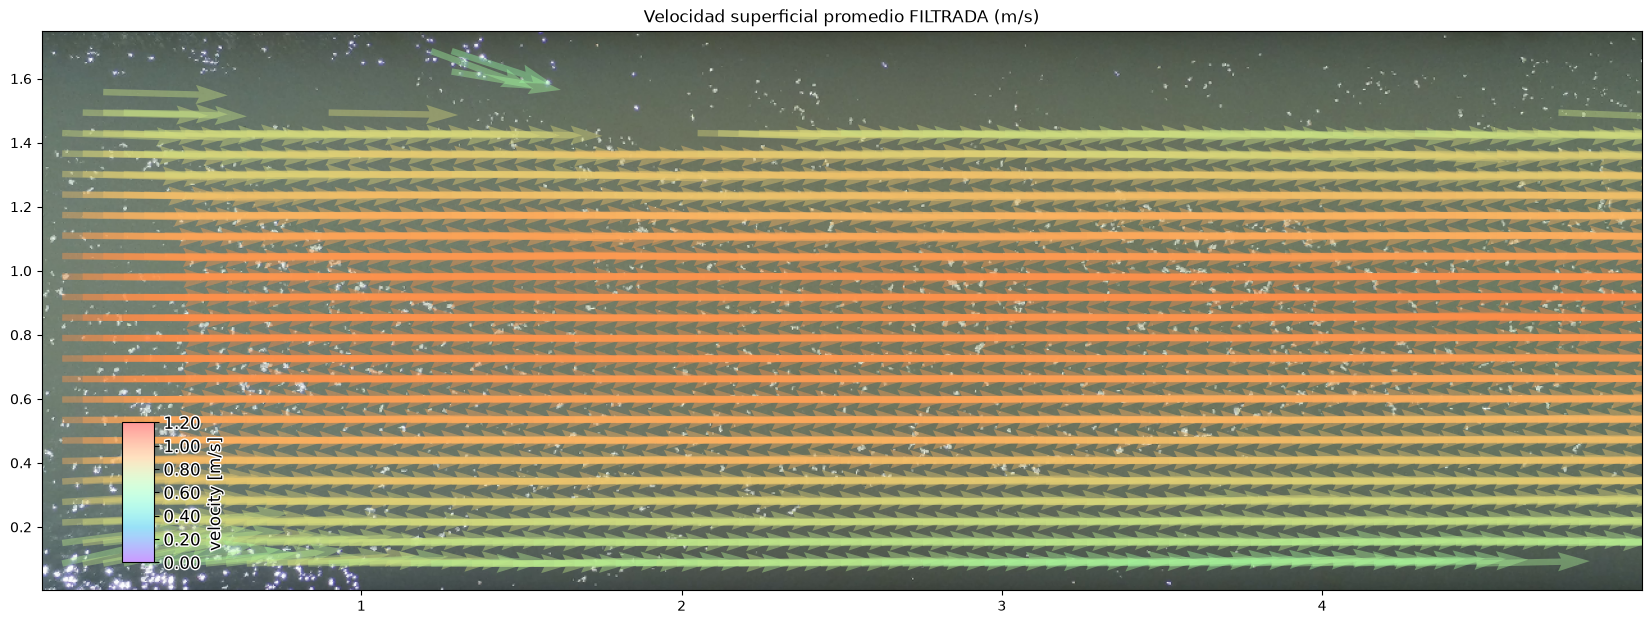

Velocimetria filtrada guardada en: salidas\piv_filtrado.nc


In [8]:
import copy

with benchmark.medir("Parte 4b: mascaras de filtrado", n_frames=N_FRAMES):         # [v2]
    # deepcopy para conservar intacto el dataset crudo y poder comparar despues.
    ds_mask = copy.deepcopy(ds)

    # [v2] Direccion dominante del flujo en el sistema local. angle_expected se mide en
    # radianes en sentido horario desde el eje vertical: 0.5*pi es "hacia +x".
    angulo_esperado = 0.5 * np.pi if float(ds["v_x"].mean()) > 0 else 1.5 * np.pi
    print(f"Velocidad media v_x = {float(ds['v_x'].mean()):+.3f} m/s "
          f"-> angle_expected = {angulo_esperado:.3f} rad")

    # --- 1) mascaras sobre valores individuales ---
    # corr: descarta ventanas cuya correlacion maxima es demasiado baja.
    ds_mask.velocimetry.mask.corr(inplace=True)
    # minmax: descarta velocidades fuera de un rango plausible.
    ds_mask.velocimetry.mask.minmax(inplace=True)

    # --- 2) mascaras en el dominio del tiempo ---
    # rolling: compara cada valor con una media movil temporal de su propia celda.
    ds_mask.velocimetry.mask.rolling(inplace=True)
    # outliers: descarta valores que se apartan demasiado de la media temporal de la celda.
    ds_mask.velocimetry.mask.outliers(inplace=True)
    # variance: descarta celdas cuya velocidad varia de forma inverosimil en el tiempo.
    ds_mask.velocimetry.mask.variance(inplace=True)

    # [v2] angle: aqui SI se aplica (inplace=True), con la direccion leida del campo.
    ds_mask.velocimetry.mask.angle(angle_expected=angulo_esperado,
                                   angle_tolerance=0.25 * np.pi, inplace=True)

    # --- 3) mascaras que necesitan toda la serie o la vecindad espacial ---
    # count: elimina las celdas que se quedaron con muy pocos valores validos.
    ds_mask.velocimetry.mask.count(inplace=True)
    # window_mean: compara cada celda con la media de su entorno de 5x5 (wdw=2) sobre el
    # promedio temporal y la descarta si se desvia mas de un 50 % (tolerance=0.5).
    ds_mask.velocimetry.mask.window_mean(wdw=2, inplace=True, tolerance=0.5, reduce_time=True)

# Promedio temporal del campo ya filtrado, para dibujar y para el mapa final.
ds_mean_mask = ds_mask.mean(dim="time", keep_attrs=True)

# count() sobre un DataArray cuenta solo los valores no nulos: sirve para medir cuanto se filtro.
n_antes = int(ds["v_x"].count())
n_despues = int(ds_mask["v_x"].count())
print(f"Vectores validos antes del filtrado: {n_antes}")
print(f"Vectores validos despues:            {n_despues} ({100 * n_despues / n_antes:.1f} %)")

p = da_rgb_proj[0].frames.plot()
ds_mean_mask.velocimetry.plot(ax=p.axes, alpha=0.4, norm=NORMA_COLOR, add_colorbar=True)
plt.title("Velocidad superficial promedio FILTRADA (m/s)")
plt.savefig(DIR_SALIDA / "fig6_velocidades_filtradas.png", dpi=110, bbox_inches="tight")
plt.show()

# Se guarda el campo filtrado sin set_encoding(), para que el archivo contenga exactamente los
# mismos valores en coma flotante que usan las celdas siguientes.
ds_mask.to_netcdf(SALIDA_PIV_FILTRADO)
print(f"Velocimetria filtrada guardada en: {SALIDA_PIV_FILTRADO}")

---
## Parte 5 - Caudal sobre la seccion

Los mismos pasos que en la v1 (`get_transect`, `get_q`, `get_river_flow`), con tres diferencias
que impone la seccion de este caso:

- **La seccion viene del CSV del aforo**: 13 verticales con su progresiva desde la orilla izquierda
  y su calado. Las de los extremos tienen calado 0: es el convenio **mid-section**, donde la primera
  y la ultima vertical marcan el borde del agua. Da 1.803 m2; la caja fisica de hormigon seria un 9 %
  mayor, pero no es lo que el aforo describe.
- **Se pasa `s=`**: sin ese argumento pyorc remuestrea la seccion a la malla de velocidades, que en la
  v1 estaba bien (batimetria con mas detalle que la malla). Aqui pasa lo contrario: remuestrear
  inventaria geometria. Y **no se pasa `crs`**: la seccion ya esta en el sistema local.
- **`V_CORR` = 0.92** en vez de 0.9, fijado antes de mirar ninguna referencia: es el mismo valor que
  usa la v3 sobre este mismo video, para que la comparacion entre las dos versiones mida el algoritmo
  y no el convenio.

In [9]:
import pandas as pd

# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Paso de velocidad superficial a media en la vertical
# ---------------------------------------------------------------------------------------
V_CORR = 0.92                 # [v2] el mismo de la v3 sobre este video; no se toca despues
# ---------------------------------------------------------------------------------------

# [v2] El CSV trae dos columnas: Progresiva (m desde la orilla izquierda) y Prof (calado, m).
seccion = pd.read_csv(ARCHIVO_SECCION)
s_transecto = seccion["Progresiva"].to_numpy(float)
prof_transecto = seccion["Prof"].to_numpy(float)
N_VERTICALES = len(s_transecto)
# [v2] Las verticales de calado nulo son los extremos: el borde del agua, no una medida.
ES_CONTORNO = prof_transecto == 0.0
AREA_SECCION = float(np.trapezoid(prof_transecto, s_transecto))
print(seccion.to_string(index=False))
print(f"\nArea de la seccion del CSV: {AREA_SECCION:.4f} m2")

# [v2] El transecto se coloca en mitad del area de interes, perpendicular al flujo: x
# constante y y recorriendo el ancho; z es la cota del lecho, el calado negado (z_0 = 0).
X_TRANSECTO = float(0.5 * (x_bbox.min() + x_bbox.max()))
x_pts = np.full(N_VERTICALES, X_TRANSECTO)
y_pts = s_transecto
z_pts = -prof_transecto

with benchmark.medir("Parte 5: get_transect + get_q", n_frames=N_FRAMES):          # [v2]
    # El muestreo se hace sobre ds_mask (filtrado), NO sobre ds (crudo): es el punto donde el
    # filtrado se traduce en el caudal.
    transect = ds_mask.velocimetry.get_transect(
        x_pts.tolist(),
        y_pts.tolist(),
        z_pts.tolist(),
        s=s_transecto.tolist(),  # [v2] respeta las 13 verticales exactas, sin remuestrear
        rolling=4,   # media movil de 4 pasos de tiempo antes de calcular los cuantiles
        # wdw=1 (por defecto) toma la mediana de una ventana de 3x3 celdas alrededor de cada punto.
    )
    # get_q convierte velocidad superficial en caudal por unidad de ancho. Los huecos sin
    # velocidad valida se rellenan ajustando un perfil logaritmico ("log_interp").
    q_transect = transect.transect.get_q(v_corr=V_CORR, fill_method="log_interp")
    # get_river_flow integra q a lo ancho de la seccion y anade river_flow al dataset.
    q_transect.transect.get_river_flow()

print(f"Transecto en x = {X_TRANSECTO:.3f} m, {transect.sizes['points']} puntos")
print(f"Cuantiles calculados: {transect['quantile'].values}")

 Progresiva  Prof
       0.00 0.000
       0.15 1.073
       0.30 1.073
       0.46 1.073
       0.61 1.073
       0.76 1.073
       0.91 1.073
       1.07 1.073
       1.22 1.073
       1.37 1.073
       1.52 1.073
       1.68 1.073
       1.83 0.000

Area de la seccion del CSV: 1.8026 m2


  [bench] Parte 5: get_transect + get_q: 3.2 s | CPU 3.2 s (1.0 nucleos) | RAM pico 1311 MB
Transecto en x = -0.140 m, 13 puntos
Cuantiles calculados: [0.05 0.25 0.5  0.75 0.95]


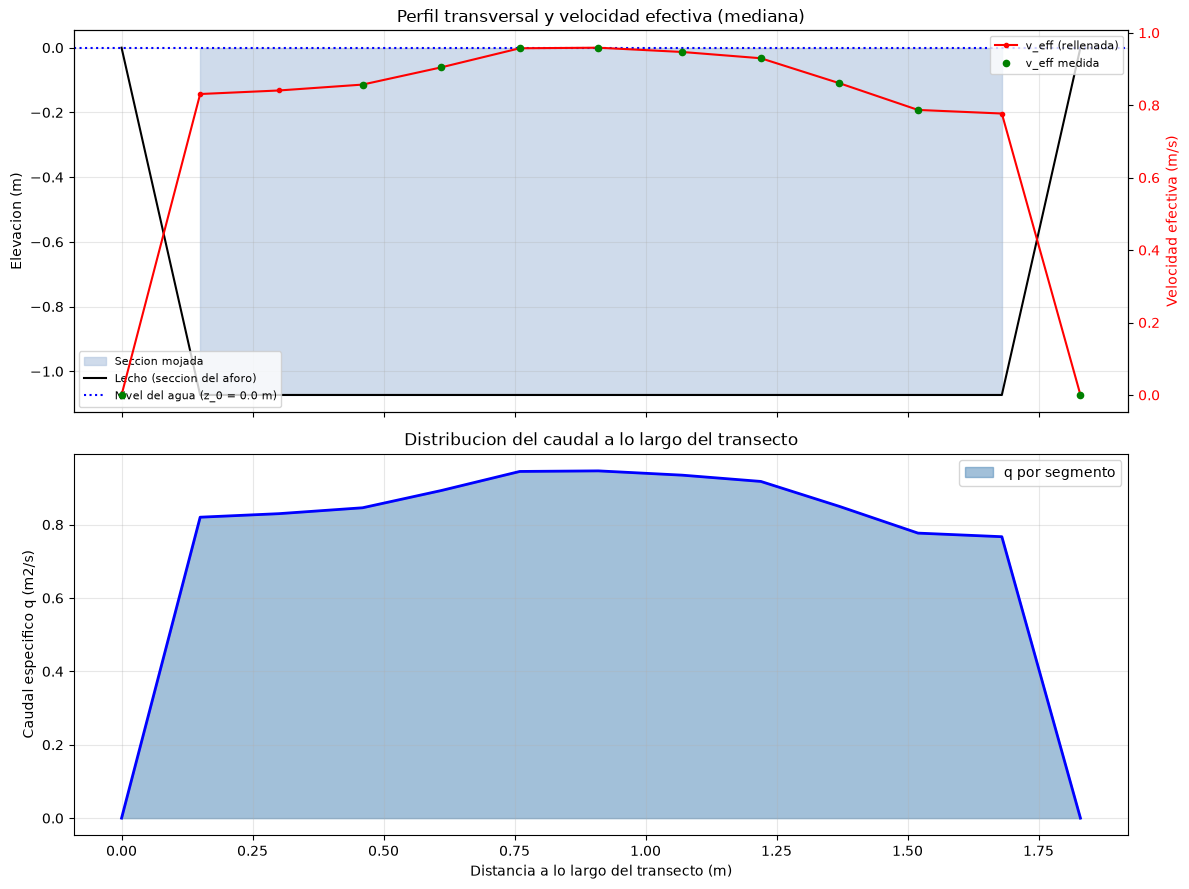

In [10]:
# quantile=0.5 es la mediana.
q_med = q_transect.sel(quantile=0.5)
v_eff = q_med["v_eff"].values                    # [v2] superficial, con huecos rellenados
v_eff_medida = q_med["v_eff_nofill"].values      # [v2] solo donde hubo medida valida
medida = np.isfinite(v_eff_medida) & ~ES_CONTORNO

# scoords es la distancia acumulada a lo largo del transecto, en metros desde una orilla.
s = q_med["scoords"].values
# La cota del agua se lee de la propia config de camara, para no repetir el numero a mano.
z_0 = ds_mask.velocimetry.camera_config.gcps["z_0"]

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

# --- Panel superior: geometria de la seccion y velocidad efectiva ---
ax_z = axes[0]
# Relleno entre el lecho y la superficie del agua, solo donde el lecho queda por debajo.
ax_z.fill_between(s, q_med["zcoords"].values, z_0,
                  where=q_med["zcoords"].values < z_0,
                  color="lightsteelblue", alpha=0.6, label="Seccion mojada")
ax_z.plot(s, q_med["zcoords"].values, "k-", lw=1.5, label="Lecho (seccion del aforo)")
ax_z.axhline(z_0, color="b", ls=":", lw=1.5, label=f"Nivel del agua (z_0 = {z_0} m)")
ax_z.set_ylabel("Elevacion (m)")
ax_z.set_title("Perfil transversal y velocidad efectiva (mediana)")
ax_z.legend(loc="lower left", fontsize=8)
ax_z.grid(True, alpha=0.3)

# twinx crea un segundo eje y que comparte el eje x, para superponer velocidades a las cotas.
ax_v = ax_z.twinx()
# v_eff: velocidad perpendicular al transecto, ya con los huecos rellenados.
ax_v.plot(s, v_eff, "r-o", ms=3, lw=1.5, label="v_eff (rellenada)")
# v_eff_nofill: solo los puntos donde realmente hubo medida valida. Los huecos delatan cuanta
# parte del perfil es interpolacion.
ax_v.plot(s, v_eff_medida, "g.", ms=9, label="v_eff medida")
ax_v.set_ylabel("Velocidad efectiva (m/s)", color="r")
ax_v.tick_params(axis="y", labelcolor="r")
ax_v.legend(loc="upper right", fontsize=8)

# --- Panel inferior: caudal especifico ---
# q es el caudal por segmento en m2/s: velocidad media en la vertical por profundidad.
axes[1].fill_between(s, q_med["q"].values, alpha=0.5, color="steelblue", label="q por segmento")
axes[1].plot(s, q_med["q"].values, "b-", lw=2)
axes[1].set_xlabel("Distancia a lo largo del transecto (m)")
axes[1].set_ylabel("Caudal especifico q (m2/s)")
axes[1].set_title("Distribucion del caudal a lo largo del transecto")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig7_perfil_transecto.png", dpi=110, bbox_inches="tight")
plt.show()

In [11]:
caudal = q_transect["river_flow"]

# [v2] Sin referencia: el caudal se calcula y se guarda; la comparacion es la Parte 7.
print("=" * 52)
print("CAUDAL POR CUANTIL (m3/s)")
print("=" * 52)
for qt in caudal["quantile"].values:
    print(f"{qt:>8.2f} {float(caudal.sel(quantile=qt)):>12.4f}")

Q_VIDEO = float(caudal.sel(quantile=0.50))   # estimacion central
q_05 = float(caudal.sel(quantile=0.05))      # limite inferior de la banda de incertidumbre
q_95 = float(caudal.sel(quantile=0.95))      # limite superior

print("-" * 52)
print(f"Caudal (mediana): {Q_VIDEO:.4f} m3/s")
print(f"Incertidumbre:    P5 = {q_05:.4f} m3/s   P95 = {q_95:.4f} m3/s")
print(f"Velocidad media:  {Q_VIDEO / AREA_SECCION:.4f} m/s")                     # [v2]
print(f"Verticales con velocidad medida: {int(medida.sum())} de "
      f"{int((~ES_CONTORNO).sum())} interiores (el resto, relleno log_interp)")   # [v2]

# [v2] El perfil vertical a vertical, para poder reanalizar sin repetir el PIV.
perfil = pd.DataFrame({
    "vertical": np.arange(N_VERTICALES),
    "s_m": s_transecto,
    "prof_m": prof_transecto,
    "v_sup_medida_ms": v_eff_medida,
    "v_sup_usada_ms": v_eff,
    "q_especifico_m2s": q_med["q"].values,
    "origen": np.where(ES_CONTORNO, "contorno (v=0 por convenio)",
                       np.where(medida, "medida", "relleno log_interp")),
})
perfil.to_csv(DIR_SALIDA / "perfil_transecto.csv", index=False)

# El transecto completo se guarda tambien en NetCDF: contiene v_eff, q, river_flow y todas las
# coordenadas del muestreo, por si se quiere reanalizar sin repetir el PIV.
q_transect.to_netcdf(SALIDA_TRANSECTO)
print(f"\nTransecto guardado en: {SALIDA_TRANSECTO}")
perfil

CAUDAL POR CUANTIL (m3/s)
    0.05       1.3545
    0.25       1.4104
    0.50       1.4545
    0.75       1.5070
    0.95       1.5792
----------------------------------------------------
Caudal (mediana): 1.4545 m3/s
Incertidumbre:    P5 = 1.3545 m3/s   P95 = 1.5792 m3/s
Velocidad media:  0.8069 m/s
Verticales con velocidad medida: 8 de 11 interiores (el resto, relleno log_interp)

Transecto guardado en: salidas\transecto_caudal.nc


,vertical,s_m,prof_m,v_sup_medida_ms,v_sup_usada_ms,q_especifico_m2s,origen
0,0,0.00,0.000,0.000000,0.000000,0.000000,contorno (v=0 por convenio)
1,1,0.15,1.073,NaN,0.830897,0.820228,relleno log_interp
2,2,0.30,1.073,NaN,0.840646,0.829852,relleno log_interp
3,3,0.46,1.073,0.856940,0.856940,0.845937,medida
4,4,0.61,1.073,0.904495,0.904495,0.892881,medida
5,5,0.76,1.073,0.957220,0.957220,0.944929,medida
6,6,0.91,1.073,0.958793,0.958793,0.946482,medida
7,7,1.07,1.073,0.946967,0.946967,0.934808,medida
8,8,1.22,1.073,0.929659,0.929659,0.917722,medida
9,9,1.37,1.073,0.860737,0.860737,0.849685,medida


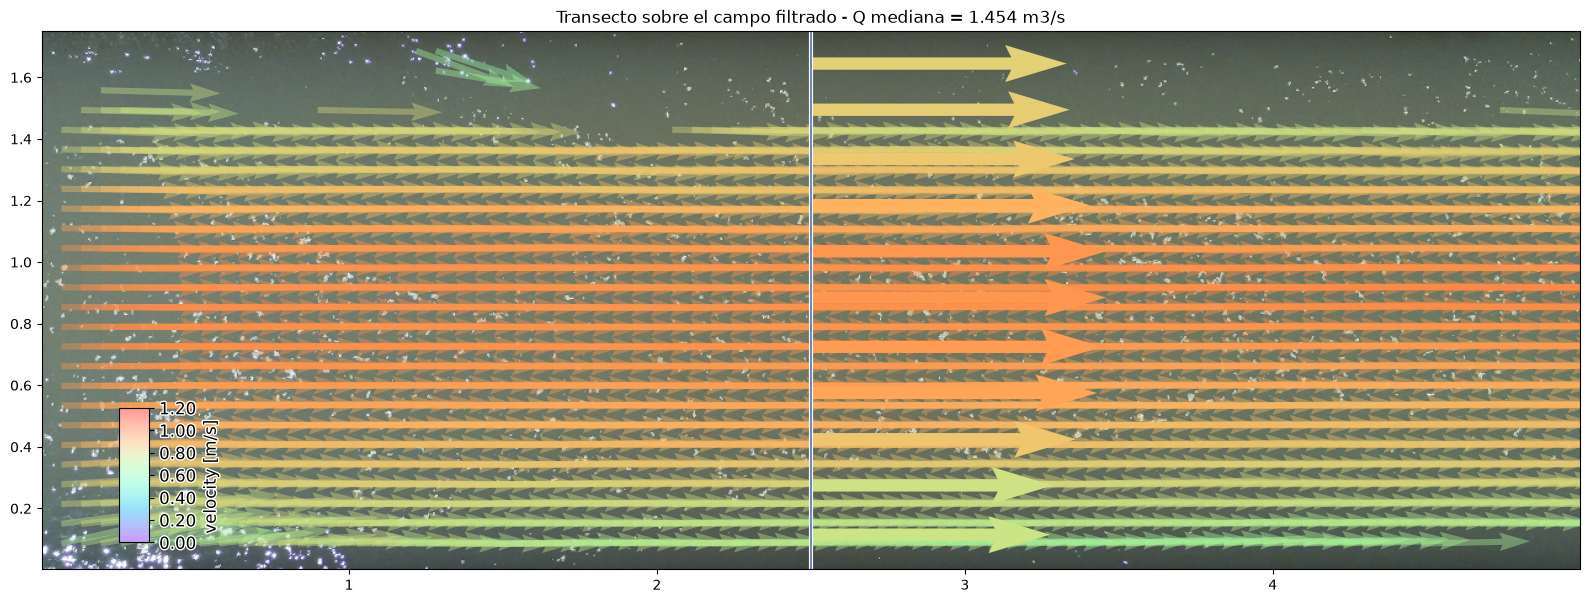

In [12]:
# Mapa final: transecto sobre el campo de velocidades filtrado.
# El fondo se dibuja en proyeccion "local" (metros desde la esquina del AOI). Se usa
# .transect.plot(), que ya conoce las coordenadas locales de cada punto muestreado.
p = da_rgb_proj[0].frames.plot(mode="local")  # fotograma ortorrectificado como fondo
ds_mean_mask.velocimetry.plot(ax=p.axes, mode="local", alpha=0.4, norm=NORMA_COLOR,
                              add_colorbar=True)
q_transect.sel(quantile=0.5).transect.plot(ax=p.axes, mode="local", cmap="rainbow",
                                           norm=NORMA_COLOR, width=2)
p.axes.set_title(f"Transecto sobre el campo filtrado - Q mediana = {Q_VIDEO:.3f} m3/s")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig8_mapa_transecto.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 6 - Recursos consumidos

Nueva en esta version. Columnas: **segundos** de reloj; **cpu_s** y **nucleos** (CPU sumando todos
los nucleos y su cociente con el reloj: 1.0 es un solo hilo saturado); **ram_pico_mb**, el maximo de
memoria residente durante la etapa, que es lo que decide si un video mas largo cabe; y
**ram_neta_mb**, lo que queda ocupado al terminar.

Maquina donde se han medido los tiempos:
  cpu_nucleos_fisicos: 12
  cpu_nucleos_logicos: 16
  ram_total_gb: 42.7
  ram_disponible_gb: 20.4

Tiempo total medido: 292.7 s
Pico de memoria del proceso: 14044 MB


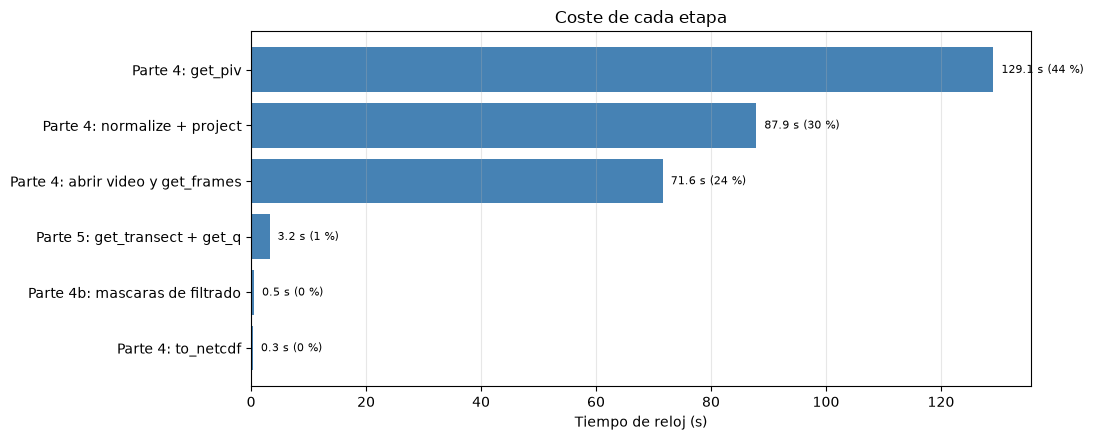

,etapa,segundos,cpu_s,nucleos,ram_pico_mb,ram_neta_mb,n_frames,pct_tiempo
0,Parte 4: abrir video y get_frames,71.62,352.39,4.92,1327.2,132.8,250,24.5
1,Parte 4: normalize + project,87.89,964.73,10.98,8951.4,107.2,250,30.0
2,Parte 4: get_piv,129.14,1318.17,10.21,14044.5,1115.3,250,44.1
3,Parte 4: to_netcdf,0.32,0.30,0.93,1978.4,-0.4,250,0.1
4,Parte 4b: mascaras de filtrado,0.51,0.52,1.00,1137.9,16.0,250,0.2
5,Parte 5: get_transect + get_q,3.21,3.16,0.98,1311.0,0.8,250,1.1


In [13]:
# [v2] Parte nueva.
print("Maquina donde se han medido los tiempos:")
for k, v in benchmark.entorno().items():
    print(f"  {k}: {v}")

tabla_recursos = benchmark.tabla()
tabla_recursos.to_csv(SALIDA_BENCHMARK, index=False)
print(f"\nTiempo total medido: {tabla_recursos['segundos'].sum():.1f} s")
print(f"Pico de memoria del proceso: {tabla_recursos['ram_pico_mb'].max():.0f} MB")

fig, ax = plt.subplots(figsize=(11, 4.5))
orden = tabla_recursos.sort_values("segundos")
ax.barh(orden["etapa"], orden["segundos"], color="steelblue")
ax.set_xlabel("Tiempo de reloj (s)")
ax.set_title("Coste de cada etapa")
ax.grid(axis="x", alpha=0.3)
for y, (seg, pct) in enumerate(zip(orden["segundos"], orden["pct_tiempo"])):
    ax.text(seg, y, f"  {seg:.1f} s ({pct:.0f} %)", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig9_recursos.png", dpi=110, bbox_inches="tight")
plt.show()
tabla_recursos

---
## Parte 7 - Comparacion con la referencia del dataset

Hasta aqui no se ha usado ni un solo dato de validacion. Ahora se abren las dos referencias del
data release:

1. **El aforo con FlowTracker** (ADV, por vadeo) del mismo dia: caudal total y velocidad media en la
   vertical de cada una de las 13 verticales. Medida **independiente**, incertidumbre ISO 4.2 %.
2. **El LSPIV del propio USGS** (`SMC_PIV_results.mat`, PIVlab). Corresponde al vuelo **020** y no al
   **022** que se procesa aqui: sirve para contrastar la **forma** del perfil, no punto a punto.

**Esta es la ultima parte del notebook. No se vuelve atras a ajustar nada.**

In [14]:
# [v2] Parte nueva.
# ---------------------------------------------------------------------------------------
#  Datos de validacion. Primera vez que aparecen en el notebook.
#  Aforo con FlowTracker (ADV, por vadeo) del 2020-08-17 11:17. (obtenido del dataset)
# ---------------------------------------------------------------------------------------
Q_AFORO = 1.4362              # m3/s, caudal total medido
AREA_AFORO = 1.799            # m2, area de la seccion segun el convenio mid-section
V_MEDIA_AFORO = 0.7985        # m/s, velocidad media en la seccion
V_ADV = np.array([0.0, 0.6298, 0.7973, 0.8132, 0.8121, 0.8220, 0.8518,   # m/s, media en la
                  0.8508, 0.8458, 0.8094, 0.8146, 0.7365, 0.0])         # vertical
# ---------------------------------------------------------------------------------------

error_rel = 100 * (Q_VIDEO / Q_AFORO - 1)
print("=" * 66)
print(f"  LSPIV (este notebook)   : {Q_VIDEO:.4f} m3/s")
print(f"  Aforo FlowTracker (ADV) : {Q_AFORO:.4f} m3/s   (incertidumbre ISO 4.2 %)")
print(f"  Diferencia              : {error_rel:+.1f} %")
print(f"  Banda del PIV           : P5 {100 * (q_05 / Q_AFORO - 1):+.1f} % .. "
      f"P95 {100 * (q_95 / Q_AFORO - 1):+.1f} % frente al aforo")
print(f"  Velocidad media         : {Q_VIDEO / AREA_SECCION:.4f} m/s  |  aforo {V_MEDIA_AFORO:.4f} m/s")
print("=" * 66)

v_media_vertical = v_eff * V_CORR
comparacion = pd.DataFrame({
    "vertical": np.arange(N_VERTICALES),
    "s_m": s_transecto,
    "v_sup": v_eff,
    "v_media": v_media_vertical,
    "v_media_ADV": V_ADV,
    "dif_pct": np.where(V_ADV > 0, 100 * (v_media_vertical / np.where(V_ADV > 0, V_ADV, 1) - 1),
                        np.nan),
    "origen": perfil["origen"],
})
print(comparacion.to_string(index=False, float_format=lambda x: f"{x:8.4f}"))

  LSPIV (este notebook)   : 1.4545 m3/s
  Aforo FlowTracker (ADV) : 1.4362 m3/s   (incertidumbre ISO 4.2 %)
  Diferencia              : +1.3 %
  Banda del PIV           : P5 -5.7 % .. P95 +10.0 % frente al aforo
  Velocidad media         : 0.8069 m/s  |  aforo 0.7985 m/s
 vertical      s_m    v_sup  v_media  v_media_ADV  dif_pct                      origen
        0   0.0000   0.0000   0.0000       0.0000      NaN contorno (v=0 por convenio)
        1   0.1500   0.8309   0.7644       0.6298  21.3759          relleno log_interp
        2   0.3000   0.8406   0.7734       0.7973  -2.9984          relleno log_interp
        3   0.4600   0.8569   0.7884       0.8132  -3.0515                      medida
        4   0.6100   0.9045   0.8321       0.8121   2.4671                      medida
        5   0.7600   0.9572   0.8806       0.8220   7.1341                      medida
        6   0.9100   0.9588   0.8821       0.8518   3.5559                      medida
        7   1.0700   0.9470   0.

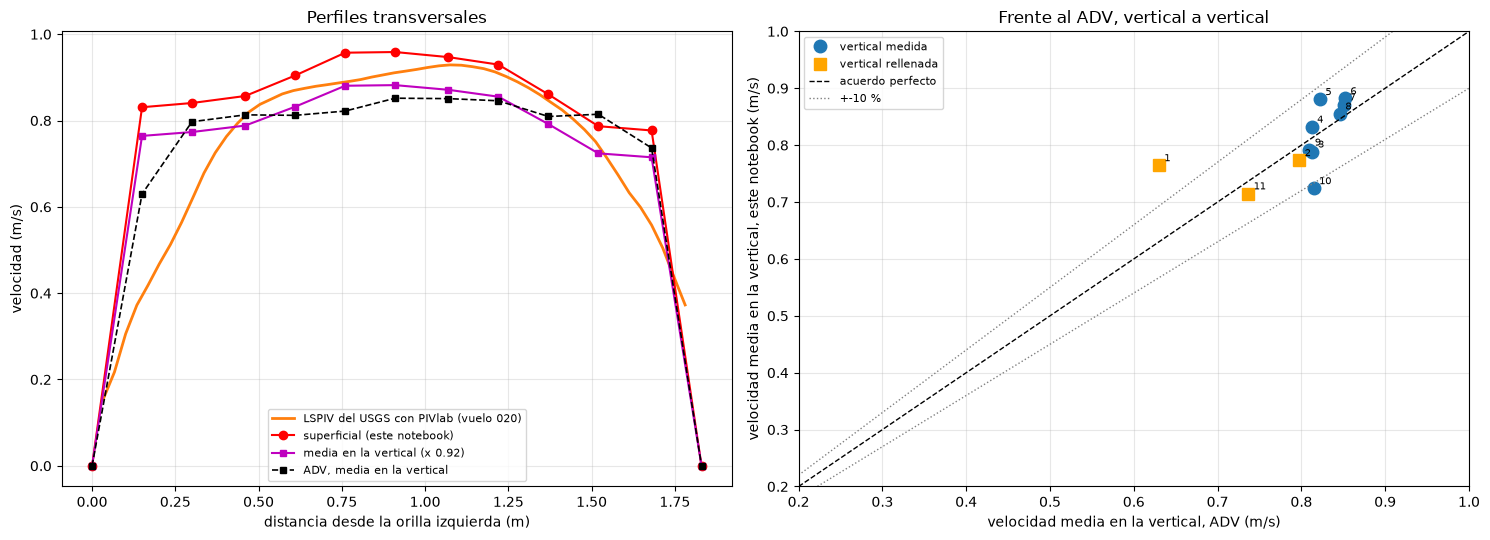

Sobre las 8 verticales medidas (se excluyen 3 rellenadas):
  Sesgo medio frente al ADV: +0.0007 m/s (+0.1 %)
  RMSE:                      0.0424 m/s
  v_corr implicito = 0.919  (el notebook uso 0.92; es un diagnostico, no una correccion)


,concepto,valor,unidad
0,Caudal (este notebook),1.454471,m3/s
1,Caudal aforo FlowTracker,1.436200,m3/s
2,Diferencia,1.272205,%
3,Cuantil 0.05,1.354457,m3/s
4,Cuantil 0.95,1.579162,m3/s
5,Verticales medidas,8.000000,de 11
6,Verticales rellenadas,3.000000,de 11
7,Sesgo frente al ADV (verticales medidas),0.000741,m/s
8,v_corr usado,0.920000,-
9,v_corr implicito segun el ADV,0.919177,-


In [15]:
from scipy.io import loadmat

mat = loadmat(str(ARCHIVO_PIV_USGS))
# u_mean y v_mean en m/s; y_ground es la coordenada transversal. Se promedia a lo largo del canal.
perfil_usgs = np.hypot(mat["u_mean"], mat["v_mean"]).mean(axis=1)
y_usgs = mat["y_ground"][:, 0]
orden_y = np.argsort(y_usgs)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
ax.plot(y_usgs[orden_y], perfil_usgs[orden_y], "-", color="tab:orange", lw=2,
        label="LSPIV del USGS con PIVlab (vuelo 020)")
ax.plot(s_transecto, v_eff, "r-o", ms=6, label="superficial (este notebook)")
ax.plot(s_transecto, v_media_vertical, "m-s", ms=5, label=f"media en la vertical (x {V_CORR})")
ax.plot(s_transecto, V_ADV, "ks--", ms=5, lw=1.2, label="ADV, media en la vertical")
ax.set_xlabel("distancia desde la orilla izquierda (m)")
ax.set_ylabel("velocidad (m/s)")
ax.set_title("Perfiles transversales")
ax.grid(alpha=0.3); ax.legend(fontsize=8)

ax = axes[1]
interior = ~ES_CONTORNO
med = interior & medida
rel = interior & ~medida
ax.plot(V_ADV[med], v_media_vertical[med], "o", ms=9, color="tab:blue", label="vertical medida")
ax.plot(V_ADV[rel], v_media_vertical[rel], "s", ms=9, color="orange", label="vertical rellenada")
lim = [0.2, 1.0]
ax.plot(lim, lim, "k--", lw=1, label="acuerdo perfecto")
ax.plot(lim, [1.1 * v for v in lim], ":", color="gray", lw=1, label="+-10 %")
ax.plot(lim, [0.9 * v for v in lim], ":", color="gray", lw=1)
for i in np.where(interior)[0]:
    ax.annotate(str(i), (V_ADV[i], v_media_vertical[i]), fontsize=7,
                xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("velocidad media en la vertical, ADV (m/s)")
ax.set_ylabel("velocidad media en la vertical, este notebook (m/s)")
ax.set_title("Frente al ADV, vertical a vertical")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig10_comparacion.png", dpi=110, bbox_inches="tight")
plt.show()

# Las estadisticas se calculan solo sobre las verticales medidas: meter las rellenadas mediria
# el relleno, no el metodo.
sesgo = float(np.mean(v_media_vertical[med] - V_ADV[med]))
rmse = float(np.sqrt(np.mean((v_media_vertical[med] - V_ADV[med]) ** 2)))
v_corr_implicito = float(V_ADV[med].mean() / v_eff[med].mean())
print(f"Sobre las {int(med.sum())} verticales medidas (se excluyen {int(rel.sum())} rellenadas):")
print(f"  Sesgo medio frente al ADV: {sesgo:+.4f} m/s ({100 * sesgo / V_ADV[med].mean():+.1f} %)")
print(f"  RMSE:                      {rmse:.4f} m/s")
print(f"  v_corr implicito = {v_corr_implicito:.3f}  (el notebook uso {V_CORR}; es un "
      "diagnostico, no una correccion)")

resumen = pd.DataFrame([
    dict(concepto="Caudal (este notebook)", valor=Q_VIDEO, unidad="m3/s"),
    dict(concepto="Caudal aforo FlowTracker", valor=Q_AFORO, unidad="m3/s"),
    dict(concepto="Diferencia", valor=error_rel, unidad="%"),
    dict(concepto="Cuantil 0.05", valor=q_05, unidad="m3/s"),
    dict(concepto="Cuantil 0.95", valor=q_95, unidad="m3/s"),
    dict(concepto="Verticales medidas", valor=int(med.sum()), unidad="de 11"),
    dict(concepto="Verticales rellenadas", valor=int(rel.sum()), unidad="de 11"),
    dict(concepto="Sesgo frente al ADV (verticales medidas)", valor=sesgo, unidad="m/s"),
    dict(concepto="v_corr usado", valor=V_CORR, unidad="-"),
    dict(concepto="v_corr implicito segun el ADV", valor=v_corr_implicito, unidad="-"),
])
resumen.to_csv(SALIDA_RESUMEN, index=False)
resumen

---
## Archivos generados

Todo queda en `salidas/`, sin tocar los datos de entrada.

In [16]:
print(f"Contenido de {DIR_SALIDA}:\n")
for archivo in sorted(DIR_SALIDA.iterdir()):
    # st_size da el tamano en bytes; se divide entre 1024 para mostrarlo en KiB.
    print(f"  {archivo.name:<34} {archivo.stat().st_size / 1024:>10.1f} KiB")

Contenido de salidas:

  benchmark_recursos.csv                    0.5 KiB
  cam_config.json                           1.7 KiB
  caudal_resumen.csv                        0.4 KiB
  fig10_comparacion.png                   126.1 KiB
  fig1_fotograma.png                      652.4 KiB
  fig2_puntos_control.png                1518.5 KiB
  fig3_area_interes.png                   650.8 KiB
  fig4_reproyeccion.png                   918.6 KiB
  fig5_velocidades_sin_filtrar.png       1280.0 KiB
  fig6_velocidades_filtradas.png         1094.4 KiB
  fig7_perfil_transecto.png               100.6 KiB
  fig8_mapa_transecto.png                1012.5 KiB
  fig9_recursos.png                        32.2 KiB
  perfil_transecto.csv                      1.0 KiB
  piv_crudo.nc                           1996.9 KiB
  piv_filtrado.nc                       15723.2 KiB
  transecto_caudal.nc                      31.7 KiB


---
## Lectura del resultado

**Lo que el metodo hace bien.** La forma del perfil transversal, con el maximo en el centro y la
caida hacia los dos muros, sale del video sin haberla impuesto en ningun sitio, y coincide con el
ADV vertical a vertical y con la forma del LSPIV que publico el USGS sobre otro vuelo.

**Donde se va el error**, por orden de peso:

1. **Las verticales pegadas a los muros son relleno, no medida.** Las ventanas de interrogacion que
   tocan el hormigon pierden correlacion y `log_interp` las reconstruye. Es la debilidad conocida
   del caso y la razon de probar otro algoritmo sobre el mismo video en la v3.
2. **`v_corr`** no se puede medir en la imagen. El ADV permite estimarlo a posteriori en las
   verticales medidas; ese numero **no se usa para corregir nada**.
3. **La escala** cuelga de dos filas de pixeles; la del muro inferior se lee sobre una rampa en sombra.

## Limitaciones conocidas

1. **El sesgo junto a los muros**: varias verticales son relleno logaritmico.
2. **La escala cuelga de dos filas de pixeles**: diez pixeles son un 1 % en el caudal.
3. **`v_corr` no es medible en la imagen.**
4. **El convenio de area**: se replica la seccion mid-section del CSV; la caja fisica es un 9 % mayor.
5. **Sin correccion de distorsion de lente**: por eso el AOI se limita a las columnas 600-3400.
6. **La referencia del USGS es de otro vuelo** (020): solo vale para la forma del perfil.
7. **La estabilizacion es un paso previo** y no se revalida aqui.